# Stroke Risk Prediction on Imbalanced Clinical Data

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR-USERNAME/stroke-prediction/blob/main/notebooks/stroke_prediction.ipynb)

**Goal.** Build a screening model that flags patients at elevated risk of stroke from routine clinical and demographic variables, and evaluate it honestly.

**Why this is harder than it looks.** Only ~5% of patients in this dataset had a stroke. A model that predicts *"no stroke"* for everyone scores ~95% accuracy while detecting **zero** strokes. This notebook is built around that problem:

| Step | What is done | Why |
|---|---|---|
| Metrics | ROC-AUC, PR-AUC, recall, precision (not accuracy) | Accuracy is meaningless at 5% prevalence |
| Split | Stratified hold-out test set, touched **once** | Unbiased final estimate |
| Preprocessing | One `Pipeline` / `ColumnTransformer`, fitted on training folds only | No data leakage |
| Missing BMI | Median imputation **plus a missing-indicator** | Missingness turns out to be informative (see EDA) |
| Encoding | One-hot for nominal variables | Integer codes impose a false order |
| Imbalance | Class weights vs. SMOTE, compared in CV | Evidence, not assumption |
| Tuning | Optimise PR-AUC | Matches the rare-event objective |
| Decision rule | Threshold chosen on out-of-fold training predictions for a target recall | Screening trade-off made explicit |
| Reporting | Bootstrap 95% confidence intervals, calibration, odds ratios | Uncertainty and interpretability |

**Dataset:** [Stroke Prediction Dataset (Kaggle, fedesoriano)](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset) - 5,110 patients, 11 features, binary target `stroke`.

| Feature | Description |
|---|---|
| `gender`, `age` | Demographics |
| `hypertension`, `heart_disease` | Binary history flags |
| `ever_married`, `work_type`, `Residence_type` | Social / demographic |
| `avg_glucose_level` | Average blood glucose (mg/dL) |
| `bmi` | Body-mass index (201 missing values) |
| `smoking_status` | never smoked / formerly smoked / smokes / Unknown |
| `stroke` | **Target** (1 = had a stroke) |

## 0. Setup

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
import xgboost
import statsmodels.formula.api as smf
from IPython.display import display, Markdown

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (make_scorer, precision_score, f1_score, recall_score, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, brier_score_loss, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

SEED = 42
TARGET_RECALL = 0.80          # screening operating point (decided before looking at test data)
N_BOOT = 1000                 # bootstrap resamples for confidence intervals

# Locate the data whether run from the repo root, from notebooks/, or from Colab after cloning
CANDIDATES = [Path('../data/healthcare-dataset-stroke-data.csv'), Path('data/healthcare-dataset-stroke-data.csv')]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Dataset not found. Download it from Kaggle (link above) into the data/ folder.')
ROOT = DATA_PATH.resolve().parent.parent
FIG_DIR, MODEL_DIR = ROOT / 'images', ROOT / 'models'
FIG_DIR.mkdir(exist_ok=True); MODEL_DIR.mkdir(exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook', font_scale=1.0)
C_NO, C_YES = '#4C72B0', '#C44E52'
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight'})

def save_fig(name):
    plt.savefig(FIG_DIR / f'{name}.png')
    plt.show()

print(f'pandas {pd.__version__} | scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__}')

pandas 3.0.6 | scikit-learn 1.9.1 | xgboost 3.4.1


## 1. Data loading and audit

In [2]:
raw = pd.read_csv(DATA_PATH)
print('Shape:', raw.shape)
print('Duplicate rows:', raw.duplicated().sum(), '| duplicate ids:', raw['id'].duplicated().sum())
display(raw.head())
display(raw.dtypes.to_frame('dtype').T)

Shape: (5110, 12)
Duplicate rows: 0 | duplicate ids: 0


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
dtype,int64,str,float64,int64,int64,str,str,str,float64,float64,str,int64


In [3]:
missing = raw.isna().sum().to_frame('n_missing')
missing['pct'] = (missing['n_missing'] / len(raw) * 100).round(2)
display(missing[missing.n_missing > 0])
display(raw.describe(include='all').T.round(2))

,n_missing,pct
bmi,201,3.93


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,5110.0,NaN,NaN,NaN,36517.829354,21161.721625,67.0,17741.25,36932.0,54682.0,72940.0
gender,5110,3,Female,2994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5110.0,NaN,NaN,NaN,43.226614,22.612647,0.08,25.0,45.0,61.0,82.0
hypertension,5110.0,NaN,NaN,NaN,0.097456,0.296607,0.0,0.0,0.0,0.0,1.0
heart_disease,5110.0,NaN,NaN,NaN,0.054012,0.226063,0.0,0.0,0.0,0.0,1.0
ever_married,5110,2,Yes,3353,NaN,NaN,NaN,NaN,NaN,NaN,NaN
work_type,5110,5,Private,2925,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Residence_type,5110,2,Urban,2596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_glucose_level,5110.0,NaN,NaN,NaN,106.147677,45.28356,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,NaN,NaN,NaN,28.893237,7.854067,10.3,23.5,28.1,33.1,97.6


**Audit notes**

- No duplicate rows or IDs. `id` carries no information, so it is dropped.
- Only `bmi` has missing values (201 rows, 3.9%).
- `gender` contains a single `Other` record. One observation cannot be learned from or stratified on, so it is removed.
- `smoking_status` has a large `Unknown` category (~30%). It is kept as its own level instead of being treated as missing.
- Outliers in `bmi` and `avg_glucose_level` are kept: extreme values are clinically plausible and the models used are robust to them (scaling is applied for the linear models).

In [4]:
df = raw.drop(columns='id')
print('Rows with gender == Other:', (df.gender == 'Other').sum())
df = df[df.gender != 'Other'].reset_index(drop=True)

NUM = ['age', 'avg_glucose_level', 'bmi']
CAT = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
BIN = ['hypertension', 'heart_disease']
FEATURES = NUM + CAT + BIN

X, y = df[FEATURES], df['stroke']
print(f'Final modelling table: {X.shape[0]} patients, {X.shape[1]} features')

Rows with gender == Other: 1
Final modelling table: 5109 patients, 10 features


## 2. Exploratory data analysis
### 2.1 Class balance

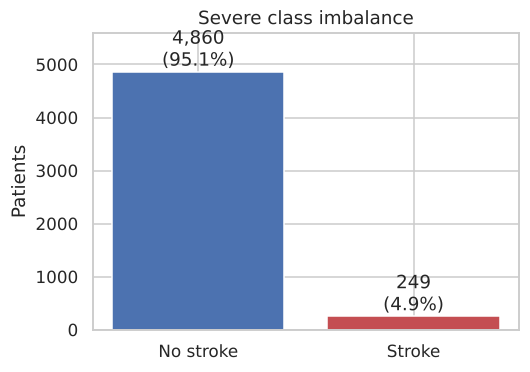

Prevalence: 4.87%. A model that always predicts "no stroke" is 95.1% accurate.


In [5]:
counts = y.value_counts().sort_index()
prevalence = y.mean()
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(['No stroke', 'Stroke'], counts.values, color=[C_NO, C_YES])
ax.bar_label(bars, labels=[f'{c:,}\n({c/len(y):.1%})' for c in counts.values])
ax.set_ylabel('Patients'); ax.set_title('Severe class imbalance'); ax.set_ylim(0, counts.max() * 1.15)
save_fig('01_class_balance')
print(f'Prevalence: {prevalence:.2%}. A model that always predicts "no stroke" is {1-prevalence:.1%} accurate.')

### 2.2 Is missing BMI informative?
Dropping rows with missing `bmi` is the default move, but it should be checked first.

,n,strokes,rate
bmi,,,
BMI missing,201,40,19.9%
BMI recorded,4908,209,4.3%


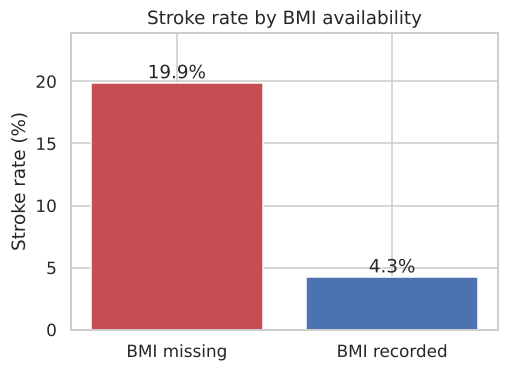

Dropping missing-BMI rows would discard 40 of 249 stroke cases (16% of all positives).


In [6]:
miss = df['bmi'].isna()
tab = (df.groupby(miss.map({True: 'BMI missing', False: 'BMI recorded'}))['stroke']
         .agg(n='size', strokes='sum', rate='mean'))
display(tab.assign(rate=(tab.rate * 100).round(1).astype(str) + '%'))

fig, ax = plt.subplots(figsize=(5, 3.5))
rates = tab['rate'] * 100
bars = ax.bar(rates.index, rates.values, color=[C_YES, C_NO])
ax.bar_label(bars, fmt='%.1f%%'); ax.set_ylabel('Stroke rate (%)')
ax.set_title('Stroke rate by BMI availability'); ax.set_ylim(0, rates.max() * 1.2)
save_fig('02_missing_bmi')

lost = int(df.loc[miss, 'stroke'].sum())
print(f'Dropping missing-BMI rows would discard {lost} of {int(y.sum())} stroke cases ({lost/y.sum():.0%} of all positives).')

**Finding.** Patients with missing BMI have a stroke rate roughly **4-5 times higher** than those with a recorded BMI. Missingness is therefore *informative* (plausibly linked to how or where these patients were assessed). Deleting these rows would throw away about one in six positive cases in an already tiny positive class. Instead, BMI is imputed with the training-set median **and a binary missing-indicator is added** so the model can use the signal.

### 2.3 Numeric features vs. stroke

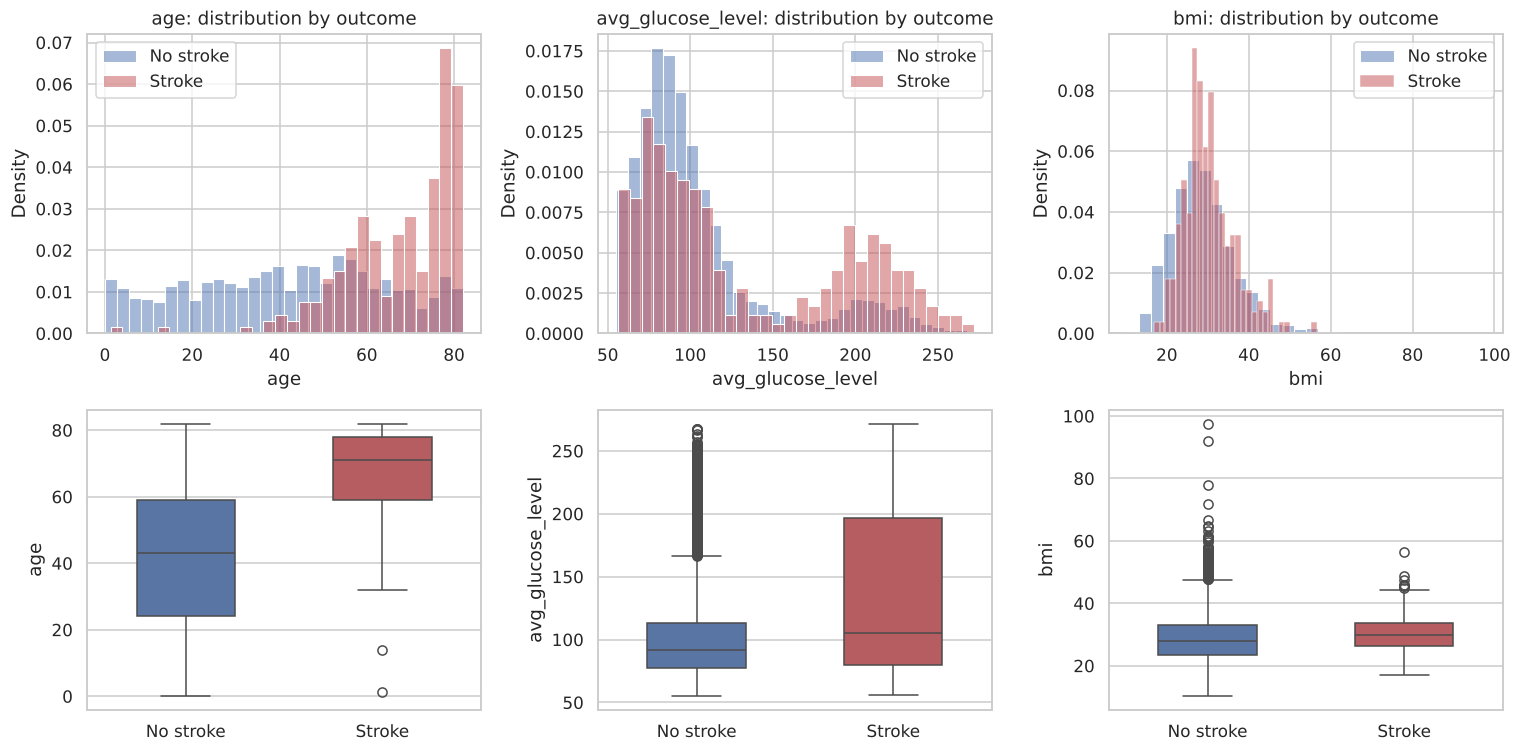

,age,avg_glucose_level,bmi
stroke,,,
No stroke,43.0,91.5,28.0
Stroke,71.0,105.2,29.7


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for j, col in enumerate(NUM):
    for label, colour, name in [(0, C_NO, 'No stroke'), (1, C_YES, 'Stroke')]:
        sns.histplot(df.loc[df.stroke == label, col].dropna(), stat='density', common_norm=False,
                     bins=30, alpha=.5, color=colour, label=name, ax=axes[0, j])
    axes[0, j].set_title(f'{col}: distribution by outcome'); axes[0, j].legend()
    sns.boxplot(data=df, x='stroke', y=col, hue='stroke', palette=[C_NO, C_YES], legend=False, ax=axes[1, j], width=.5)
    axes[1, j].set_xticks([0, 1]); axes[1, j].set_xticklabels(['No stroke', 'Stroke']); axes[1, j].set_xlabel('')
plt.tight_layout()
save_fig('03_numeric_features')
display(df.groupby('stroke')[NUM].median().round(1).rename(index={0: 'No stroke', 1: 'Stroke'}))

Age shows by far the clearest separation (stroke patients are much older). Glucose is bimodal, with a high-glucose mode that is over-represented among stroke patients. BMI separates the groups only weakly.

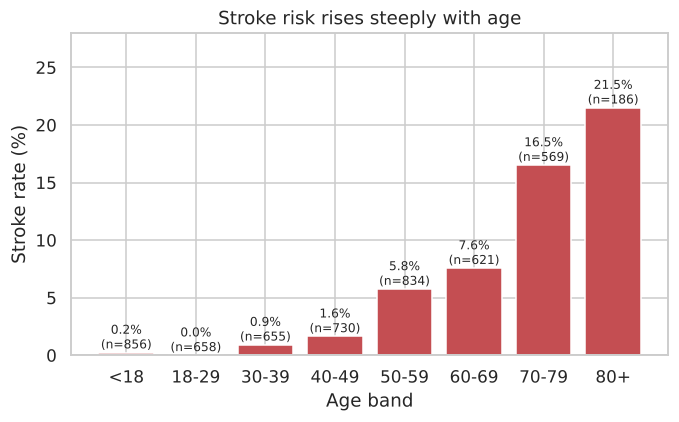

In [8]:
df['age_band'] = pd.cut(df.age, bins=[0, 18, 30, 40, 50, 60, 70, 80, 100],
                        labels=['<18', '18-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80+'], right=False)
band = df.groupby('age_band', observed=True)['stroke'].agg(['mean', 'size'])
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(band.index.astype(str), band['mean'] * 100, color=C_YES)
ax.bar_label(bars, labels=[f'{m:.1%}\n(n={n})' for m, n in zip(band['mean'], band['size'])], fontsize=8)
ax.set_ylabel('Stroke rate (%)'); ax.set_xlabel('Age band'); ax.set_ylim(0, band['mean'].max() * 100 * 1.3)
ax.set_title('Stroke risk rises steeply with age')
save_fig('04_stroke_rate_by_age')
df = df.drop(columns='age_band')

### 2.4 Categorical features vs. stroke

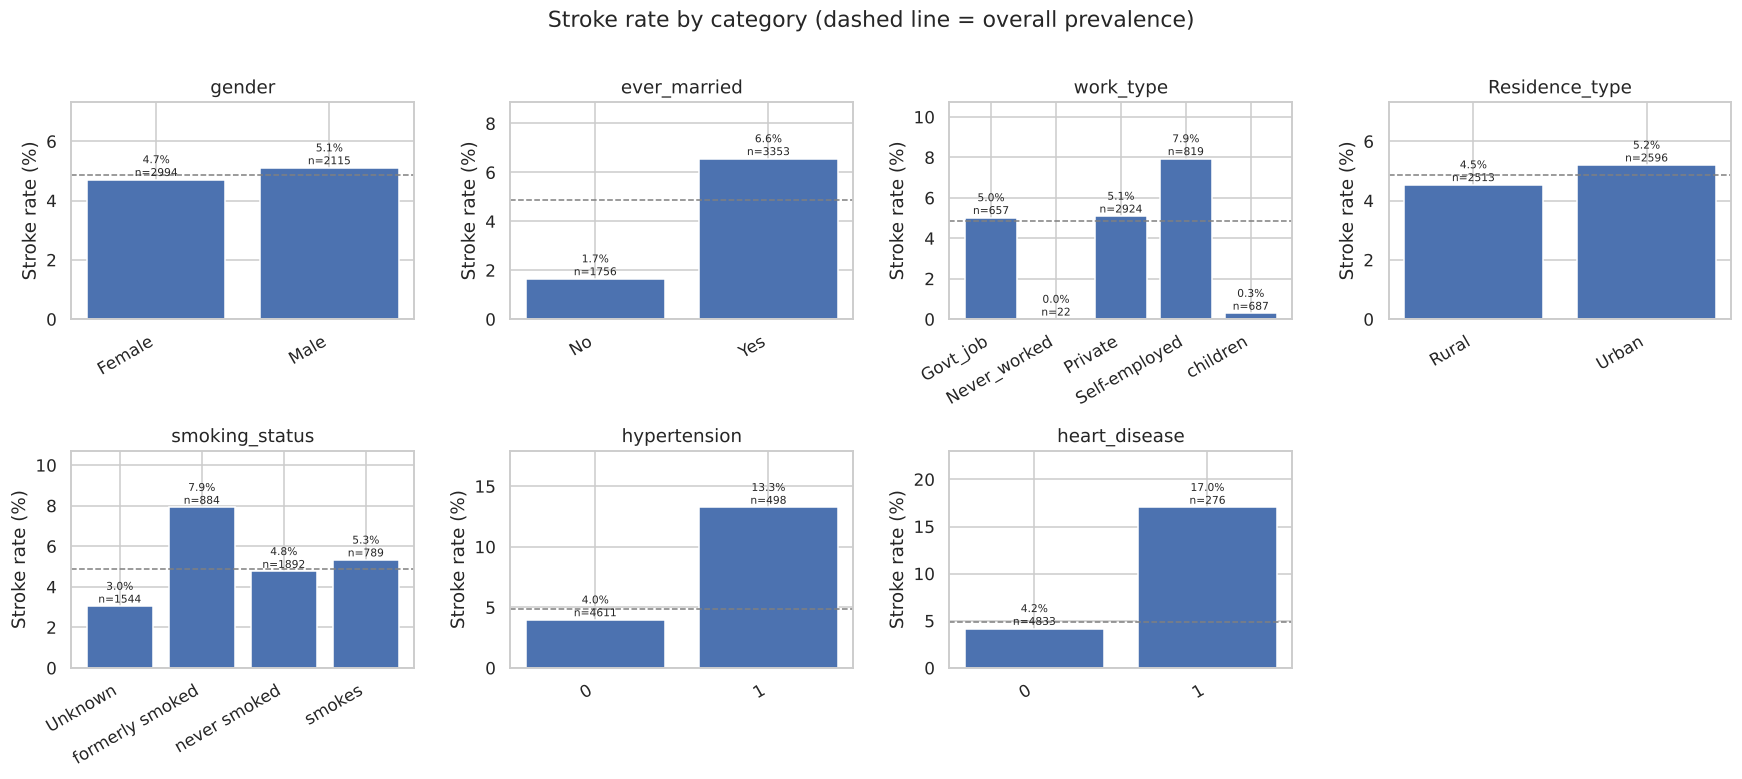

In [9]:
cat_all = CAT + BIN
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
overall = y.mean() * 100
for ax, col in zip(axes.ravel(), cat_all):
    g = df.groupby(col)['stroke'].agg(['mean', 'size'])
    bars = ax.bar(g.index.astype(str), g['mean'] * 100, color=C_NO)
    ax.bar_label(bars, labels=[f'{m:.1%}\nn={n}' for m, n in zip(g['mean'], g['size'])], fontsize=7)
    ax.axhline(overall, color='grey', ls='--', lw=1)
    ax.set_title(col); ax.set_ylabel('Stroke rate (%)'); ax.tick_params(axis='x', rotation=30)
    for lbl in ax.get_xticklabels(): lbl.set_ha('right')
    ax.set_ylim(0, max(g['mean'].max() * 100 * 1.35, overall * 1.5))
axes.ravel()[-1].axis('off')
fig.suptitle('Stroke rate by category (dashed line = overall prevalence)', y=1.01)
plt.tight_layout()
save_fig('05_stroke_rate_by_category')

Hypertension (13%) and heart disease (17%) are associated with roughly 3-4x the stroke rate of patients without them (4%). `ever_married` and `work_type` look predictive on their own, but this is largely **confounded by age** (children are never married and have `work_type = children`; the Never_worked group has only 22 patients). Residence type and gender carry little signal. The 'formerly smoked' bump (7.9%) is also likely an age effect, because former smokers are older. Several categories are small, so rates there should not be over-interpreted.

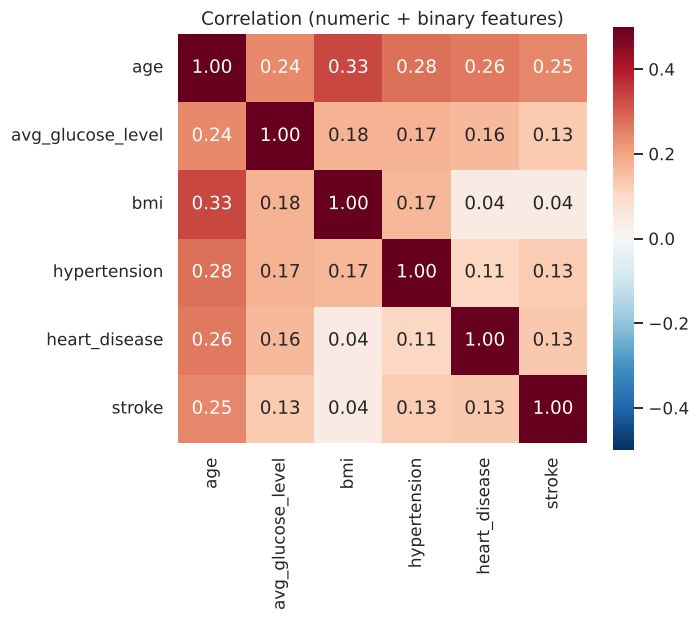

In [10]:
corr = df[NUM + BIN + ['stroke']].corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-.5, vmax=.5, square=True, ax=ax)
ax.set_title('Correlation (numeric + binary features)')
save_fig('06_correlation')

## 3. Train / test split and preprocessing
The test set is split off **first**, stratified on the outcome so both sets keep the same ~5% prevalence, and is not used again until the final evaluation. All model selection, tuning and threshold choice use the training set only.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
display(pd.DataFrame({'patients': [len(y_train), len(y_test)],
                      'strokes': [y_train.sum(), y_test.sum()],
                      'prevalence': [f'{y_train.mean():.2%}', f'{y_test.mean():.2%}']}, index=['train', 'test']))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

,patients,strokes,prevalence
train,4087,199,4.87%
test,1022,50,4.89%


Preprocessing lives inside the model pipeline, so scaling and imputation statistics are learned from each training fold only (the original notebook scaled the full dataset before splitting, which leaks test information).

- **Numeric:** median imputation + missing-indicator (only `bmi` ever triggers it), then standardisation
- **Nominal categorical:** one-hot encoding (binary variables become a single 0/1 column)
- **Binary flags:** passed through

In [12]:
def make_preprocessor():
    return ColumnTransformer([
        ('num', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                          ('scale', StandardScaler())]), NUM),
        ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), CAT),
        ('bin', 'passthrough', BIN),
    ])

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos
print(f'Training class ratio neg:pos = {neg}:{pos} (scale_pos_weight = {scale_pos_weight:.1f})')

Training class ratio neg:pos = 3888:199 (scale_pos_weight = 19.5)


## 4. Baselines and model comparison (5-fold stratified CV on the training set)
The same candidates as the original notebook (Logistic Regression, Random Forest, SVC, Decision Tree, KNN) plus XGBoost and a **dummy baseline**. Accuracy is deliberately shown next to the rare-event metrics to illustrate why it is misleading here. All metrics except ROC-AUC and PR-AUC use the default 0.5 / 0-score decision rule at this stage; threshold selection comes later.

In [13]:
scoring = {
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision',
    'recall': make_scorer(recall_score, zero_division=0),
    'precision': make_scorer(precision_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'accuracy': 'accuracy',
}

candidates = {
    'Dummy (prior)':        DummyClassifier(strategy='prior'),
    'Logistic Regression':  LogisticRegression(class_weight='balanced', max_iter=2000),
    'Random Forest':        RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                   class_weight='balanced_subsample', random_state=SEED, n_jobs=-1),
    'XGBoost':              XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8,
                                          colsample_bytree=0.8, scale_pos_weight=scale_pos_weight,
                                          eval_metric='logloss', random_state=SEED, n_jobs=-1),
    'SVC (RBF)':            SVC(class_weight='balanced'),
    'Decision Tree':        DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=SEED),
    'KNN (k=25)':           KNeighborsClassifier(n_neighbors=25),
}

def cv_summary(estimators):
    rows = {}
    for name, est in estimators.items():
        pipe = Pipeline([('prep', make_preprocessor()), ('model', est)])
        res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
        rows[name] = {k.replace('test_', ''): res[k].mean() for k in res if k.startswith('test_')}
        rows[name].update({f'{k.replace("test_", "")}_sd': res[k].std() for k in res if k.startswith('test_')})
    return pd.DataFrame(rows).T

comparison = cv_summary(candidates)
cols = ['roc_auc', 'pr_auc', 'recall', 'precision', 'f1', 'accuracy']
display(comparison[cols].sort_values('pr_auc', ascending=False).round(3))

,roc_auc,pr_auc,recall,precision,f1,accuracy
Logistic Regression,0.854,0.225,0.799,0.142,0.242,0.755
Random Forest,0.846,0.224,0.307,0.239,0.267,0.919
XGBoost,0.828,0.216,0.674,0.142,0.234,0.785
Decision Tree,0.821,0.183,0.784,0.127,0.218,0.722
KNN (k=25),0.779,0.183,0.000,0.000,0.000,0.951
SVC (RBF),0.816,0.152,0.679,0.131,0.220,0.767
Dummy (prior),0.500,0.049,0.000,0.000,0.000,0.951


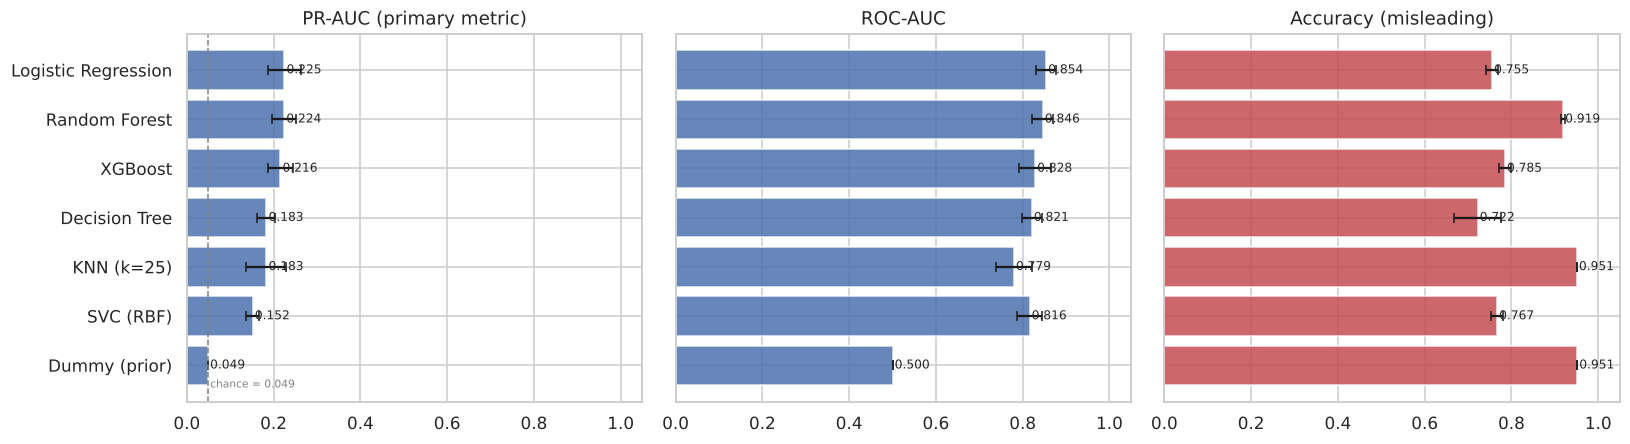

In [14]:
order = comparison.sort_values('pr_auc', ascending=True).index
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, metric, title in zip(axes, ['pr_auc', 'roc_auc', 'accuracy'],
                             ['PR-AUC (primary metric)', 'ROC-AUC', 'Accuracy (misleading)']):
    vals = comparison.loc[order, metric]; err = comparison.loc[order, f'{metric}_sd']
    colour = C_YES if metric == 'accuracy' else C_NO
    ax.barh(order, vals, xerr=err, color=colour, alpha=.85, capsize=3)
    for i, v in enumerate(vals): ax.text(v + .005, i, f'{v:.3f}', va='center', fontsize=8)
    ax.set_title(title); ax.set_xlim(0, 1.05)
axes[0].axvline(prevalence, color='grey', ls='--', lw=1)
axes[0].text(prevalence + .005, -0.45, f'chance = {prevalence:.3f}', fontsize=7, color='grey')
plt.tight_layout()
save_fig('07_model_comparison')

**Reading the table**

- The dummy model gets ~95% accuracy and 0 recall: this is what the original notebook's tree, SVC and KNN models were effectively doing.
- Rankings by accuracy and by PR-AUC disagree completely. PR-AUC (chance level = prevalence ~0.05) is the metric used for selection.
- KNN has no `class_weight` option and flags almost nobody at the default threshold, despite a decent AUC.
- Once preprocessing is correct, a **simple regularised logistic regression is competitive with the flexible models**, which is common on small tabular clinical datasets with ~200 positive cases.

### 4.1 Class weights vs. SMOTE
Is synthetic oversampling worth it? SMOTE is placed **inside** the CV pipeline so synthetic samples are generated from training folds only.

In [15]:
def pipe_with(sampler, est):
    steps = [('prep', make_preprocessor())]
    if sampler is not None: steps.append(('smote', sampler))
    steps.append(('model', est))
    return ImbPipeline(steps)

variants = {
    'LR + class weights':  pipe_with(None, LogisticRegression(class_weight='balanced', max_iter=2000)),
    'LR + SMOTE':          pipe_with(SMOTE(random_state=SEED), LogisticRegression(max_iter=2000)),
    'LR (no handling)':    pipe_with(None, LogisticRegression(max_iter=2000)),
    'RF + class weights':  pipe_with(None, RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced_subsample', random_state=SEED, n_jobs=-1)),
    'RF + SMOTE':          pipe_with(SMOTE(random_state=SEED), RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1)),
}
rows = {}
for name, p in variants.items():
    r = cross_validate(p, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows[name] = {m: r[f'test_{m}'].mean() for m in ['roc_auc', 'pr_auc', 'recall', 'precision']}
imbalance_cmp = pd.DataFrame(rows).T
display(imbalance_cmp.round(3))

,roc_auc,pr_auc,recall,precision
LR + class weights,0.854,0.225,0.799,0.142
LR + SMOTE,0.849,0.226,0.784,0.140
LR (no handling),0.853,0.227,0.025,0.273
RF + class weights,0.846,0.224,0.307,0.239
RF + SMOTE,0.825,0.162,0.191,0.200


- For logistic regression, SMOTE, class weights and **no handling at all** give the same PR-AUC (~0.23). The only thing that differs is recall at the default 0.5 threshold (0.03 without handling vs. ~0.8 with either fix), i.e. imbalance handling mostly *moves the operating point*, which the threshold step in Section 6 controls directly. Ranking quality (AUC) is unchanged.
- For random forest, SMOTE actually **hurts** PR-AUC (0.16 vs. 0.22).

SMOTE therefore earns no place in the pipeline: class weights or a tuned threshold are simpler and avoid synthetic-sample artefacts. Class weights are kept as a hyper-parameter in the search below.

## 5. Hyper-parameter tuning (optimising PR-AUC)
The top three model families are tuned with cross-validated search on the training set. The original notebook optimised accuracy, which is why its searches selected models that predicted all negatives.

In [16]:
def tune(name, est, param_grid, search='grid', n_iter=15):
    pipe = Pipeline([('prep', make_preprocessor()), ('model', est)])
    grid = {f'model__{k}': v for k, v in param_grid.items()}
    if search == 'grid':
        s = GridSearchCV(pipe, grid, scoring='average_precision', cv=cv, n_jobs=1)
    else:
        s = RandomizedSearchCV(pipe, grid, n_iter=n_iter, scoring='average_precision', cv=cv, random_state=SEED, n_jobs=1)
    s.fit(X_train, y_train)
    print(f'{name:20s} best CV PR-AUC = {s.best_score_:.3f} | {s.best_params_}')
    return s

searches = {}
searches['Logistic Regression'] = tune('Logistic Regression', LogisticRegression(max_iter=5000),
    {'C': [0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10], 'class_weight': ['balanced', None]})

searches['Random Forest'] = tune('Random Forest', RandomForestClassifier(random_state=SEED, n_jobs=-1),
    {'n_estimators': [200, 400], 'max_depth': [3, 5, 8, None], 'min_samples_leaf': [3, 5, 10, 20],
     'max_features': ['sqrt', 0.5], 'class_weight': ['balanced_subsample', None]}, search='random')

searches['XGBoost'] = tune('XGBoost', XGBClassifier(eval_metric='logloss', random_state=SEED, n_jobs=-1),
    {'n_estimators': [100, 200, 400], 'max_depth': [2, 3, 4], 'learning_rate': [0.01, 0.03, 0.05, 0.1],
     'subsample': [0.7, 0.9], 'colsample_bytree': [0.7, 0.9], 'min_child_weight': [1, 5, 10],
     'scale_pos_weight': [1, scale_pos_weight / 2, scale_pos_weight]}, search='random')

tuned = pd.Series({k: v.best_score_ for k, v in searches.items()}).sort_values(ascending=False)
best_name = tuned.index[0]
display(Markdown(f'**Selected model family: {best_name}** (CV PR-AUC {tuned.iloc[0]:.3f}). '
                 'The three tuned families score within about 0.02-0.03 PR-AUC of each other, which is small relative to fold-to-fold variation, so the ranking should not be over-read.'))

Logistic Regression  best CV PR-AUC = 0.230 | {'model__C': 3, 'model__class_weight': None}


Random Forest        best CV PR-AUC = 0.254 | {'model__n_estimators': 200, 'model__min_samples_leaf': 20, 'model__max_features': 0.5, 'model__max_depth': 5, 'model__class_weight': None}


XGBoost              best CV PR-AUC = 0.232 | {'model__subsample': 0.7, 'model__scale_pos_weight': np.float64(9.768844221105528), 'model__n_estimators': 200, 'model__min_child_weight': 5, 'model__max_depth': 3, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.9}


**Selected model family: Random Forest** (CV PR-AUC 0.254). The three tuned families score within about 0.02-0.03 PR-AUC of each other, which is small relative to fold-to-fold variation, so the ranking should not be over-read.

> **Note on optimism.** The CV score of a tuned model is slightly optimistic because the same folds were used to pick hyper-parameters. That is exactly why a separate hold-out test set exists: the numbers in Section 7 are the honest estimate.

## 6. Calibration and decision threshold
Two final modelling decisions, both made **using training data only**:

1. **Calibration.** Class-weighted models produce inflated probabilities, and tree ensembles are often mis-calibrated too. To report a meaningful *risk* (e.g. "8%") the selected pipeline is wrapped in `CalibratedClassifierCV` (sigmoid, 5-fold); Section 7.1 checks whether it actually helped.
2. **Threshold.** For screening, missing a stroke is costlier than a false alarm. The threshold is set to the **highest value that still reaches ≥ 80% recall on out-of-fold training predictions**.

In [17]:
best_pipe = searches[best_name].best_estimator_
final_model = CalibratedClassifierCV(best_pipe, method='sigmoid', cv=5)

# Out-of-fold calibrated probabilities on the TRAINING set (nested CV: no test data used)
oof = cross_val_predict(final_model, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
ok = rec[:-1] >= TARGET_RECALL
threshold = float(thr[ok].max())
print(f'Chosen threshold = {threshold:.3f}  ->  OOF recall = {recall_score(y_train, oof >= threshold):.2f}, '
      f'OOF precision = {precision_score(y_train, oof >= threshold):.2f}')

_ = final_model.fit(X_train, y_train)

Chosen threshold = 0.037  ->  OOF recall = 0.80, OOF precision = 0.14


## 7. Final evaluation on the untouched test set

In [18]:
p_test = final_model.predict_proba(X_test)[:, 1]
pred = (p_test >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

def point_metrics(y_true, p, thr):
    yh = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, yh, labels=[0, 1]).ravel()
    return {'ROC-AUC': roc_auc_score(y_true, p), 'PR-AUC': average_precision_score(y_true, p),
            'Recall (sensitivity)': tp / (tp + fn), 'Specificity': tn / (tn + fp),
            'Precision (PPV)': tp / (tp + fp) if tp + fp else 0.0, 'NPV': tn / (tn + fn) if tn + fn else 0.0}

# Bootstrap 95% CIs (resampling test patients)
rng = np.random.default_rng(SEED)
y_arr = y_test.to_numpy()
boots = []
for _ in range(N_BOOT):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[idx].sum() == 0: continue
    boots.append(point_metrics(y_arr[idx], p_test[idx], threshold))
boots = pd.DataFrame(boots)
point = point_metrics(y_arr, p_test, threshold)
report = pd.DataFrame({'Estimate': point,
                       '95% CI low': boots.quantile(.025), '95% CI high': boots.quantile(.975)}).round(3)
display(report)

flag_rate = pred.mean()
print(f'Threshold {threshold:.3f}: {tp} of {tp+fn} strokes caught, {fp} false alarms among {tn+fp} non-stroke patients.')
print(f'{flag_rate:.1%} of patients are flagged; about 1 in {1/point["Precision (PPV)"]:.0f} flagged patients has a stroke '
      f'(baseline prevalence 1 in {1/y_test.mean():.0f}).')

,Estimate,95% CI low,95% CI high
ROC-AUC,0.837,0.782,0.890
PR-AUC,0.235,0.150,0.353
Recall (sensitivity),0.800,0.686,0.911
Specificity,0.758,0.733,0.785
Precision (PPV),0.145,0.104,0.189
NPV,0.987,0.978,0.995


Threshold 0.037: 40 of 50 strokes caught, 235 false alarms among 972 non-stroke patients.
26.9% of patients are flagged; about 1 in 7 flagged patients has a stroke (baseline prevalence 1 in 20).


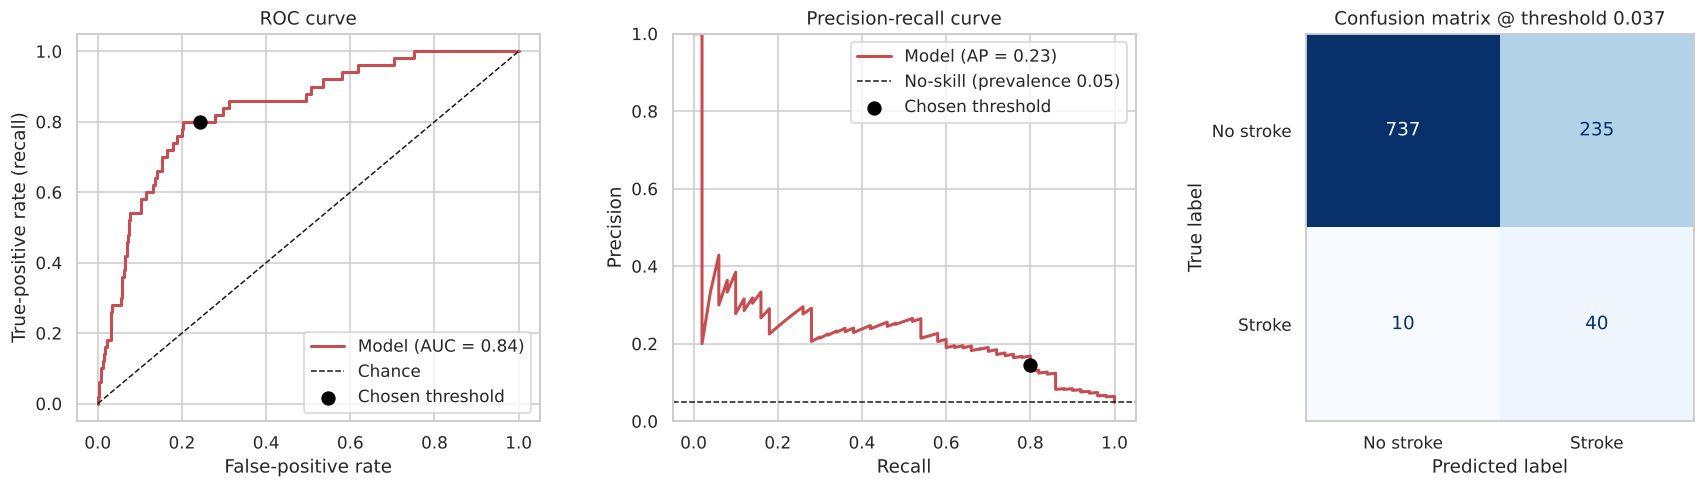

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

fpr, tpr, _ = roc_curve(y_test, p_test)
axes[0].plot(fpr, tpr, color=C_YES, lw=2, label=f'Model (AUC = {point["ROC-AUC"]:.2f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Chance')
axes[0].scatter([1 - point['Specificity']], [point['Recall (sensitivity)']], s=70, color='black', zorder=5, label='Chosen threshold')
axes[0].set(xlabel='False-positive rate', ylabel='True-positive rate (recall)', title='ROC curve'); axes[0].legend(loc='lower right')

pr_p, pr_r, _ = precision_recall_curve(y_test, p_test)
axes[1].plot(pr_r, pr_p, color=C_YES, lw=2, label=f'Model (AP = {point["PR-AUC"]:.2f})')
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1, label=f'No-skill (prevalence {y_test.mean():.2f})')
axes[1].scatter([point['Recall (sensitivity)']], [point['Precision (PPV)']], s=70, color='black', zorder=5, label='Chosen threshold')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision-recall curve', ylim=(0, 1)); axes[1].legend()

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['No stroke', 'Stroke']).plot(
    ax=axes[2], cmap='Blues', colorbar=False, values_format='d')
axes[2].set_title(f'Confusion matrix @ threshold {threshold:.3f}'); axes[2].grid(False)
plt.tight_layout()
save_fig('08_test_performance')

### 7.1 Calibration

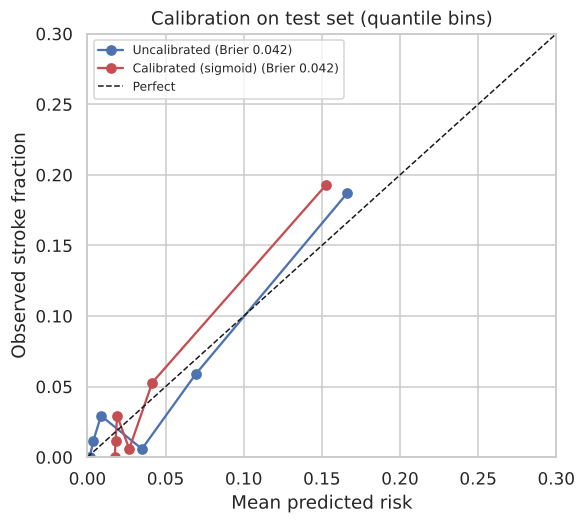

Brier score of a model that always predicts the prevalence: 0.047


In [20]:
raw_model = best_pipe.fit(X_train, y_train)          # same pipeline, uncalibrated
p_raw = raw_model.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(figsize=(5.5, 5))
for p, label, colour in [(p_raw, 'Uncalibrated', C_NO), (p_test, 'Calibrated (sigmoid)', C_YES)]:
    frac, mean_pred = calibration_curve(y_test, p, n_bins=6, strategy='quantile')
    ax.plot(mean_pred, frac, 'o-', label=f'{label} (Brier {brier_score_loss(y_test, p):.3f})', color=colour)
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Perfect')
ax.set(xlabel='Mean predicted risk', ylabel='Observed stroke fraction', title='Calibration on test set (quantile bins)', xlim=(0, .3), ylim=(0, .3))
ax.legend(loc='upper left', fontsize=8)
save_fig('09_calibration')
brier_ref = y_test.mean() * (1 - y_test.mean())
print(f'Brier score of a model that always predicts the prevalence: {brier_ref:.3f}')

The tuned model ended up **unweighted** and shallow, so its raw probabilities were already reasonably close to observed frequencies and sigmoid calibration leaves the Brier score essentially unchanged. Calibration is kept as a safeguard (a class-weighted model would have needed it badly), and the predicted risks now read as genuine probabilities: patients predicted at ~15% had roughly 15-20% observed stroke frequency. The Brier score is only modestly below the 'always predict the prevalence' reference, consistent with moderate discrimination. With only 50 test strokes, the curve is noisy and the low-risk bins are not reliably distinguishable.

### 7.2 Does the model beat age alone?
Age is such a strong predictor that a fair question is whether the extra variables add anything. An age-only logistic regression is the natural baseline.

In [21]:
age_model = Pipeline([('scale', StandardScaler()), ('lr', LogisticRegression())]).fit(X_train[['age']], y_train)
p_age = age_model.predict_proba(X_test[['age']])[:, 1]

rng = np.random.default_rng(SEED)
d_roc, d_pr = [], []
for _ in range(N_BOOT):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[idx].sum() == 0: continue
    d_roc.append(roc_auc_score(y_arr[idx], p_test[idx]) - roc_auc_score(y_arr[idx], p_age[idx]))
    d_pr.append(average_precision_score(y_arr[idx], p_test[idx]) - average_precision_score(y_arr[idx], p_age[idx]))

cmp = pd.DataFrame({
    'Age only':   [roc_auc_score(y_test, p_age),  average_precision_score(y_test, p_age)],
    'Full model': [roc_auc_score(y_test, p_test), average_precision_score(y_test, p_test)]}, index=['ROC-AUC', 'PR-AUC']).round(3)
display(cmp)
lo_r, hi_r = np.percentile(d_roc, [2.5, 97.5]); lo_p, hi_p = np.percentile(d_pr, [2.5, 97.5])
display(Markdown(f'Paired bootstrap difference (full - age only): ROC-AUC **{np.mean(d_roc):+.3f}** (95% CI {lo_r:+.3f} to {hi_r:+.3f}); '
                 f'PR-AUC **{np.mean(d_pr):+.3f}** (95% CI {lo_p:+.3f} to {hi_p:+.3f}).'))

,Age only,Full model
ROC-AUC,0.835,0.837
PR-AUC,0.209,0.235


Paired bootstrap difference (full - age only): ROC-AUC **+0.003** (95% CI -0.020 to +0.030); PR-AUC **+0.028** (95% CI -0.042 to +0.113).

**An important and honest result.** Age alone achieves essentially the same ROC-AUC as the full model, and the paired bootstrap confidence intervals for the improvement in both ROC-AUC and PR-AUC **include zero**. The point estimate for PR-AUC is higher with the full model (0.235 vs. 0.209), but with only 50 test strokes this cannot be distinguished from noise. In other words, in this dataset **age carries nearly all of the predictive signal** and glucose, hypertension and the BMI-missing flag add at most a small increment. This is a common pattern in stroke data, and it is more useful to state it plainly than to report the full model as a big win.

## 8. Interpretation
### 8.1 Odds ratios (logistic regression with confidence intervals)
Prediction is only half the story for biostatistics: *which factors are associated with stroke, and how strongly?* A classical logistic regression is fitted on the training data with clinically scaled predictors. `work_type` is omitted here because it is almost a function of age and has an empty cell (no strokes among 'Never_worked'), which causes quasi-separation.

,OR,lo,hi,p
Ever married (vs no),0.745,0.457,1.216,0.239
Smoking: Unknown (vs never),1.030,0.663,1.601,0.895
Male (vs female),1.044,0.761,1.431,0.790
BMI (per 5 kg/m²),1.049,0.925,1.190,0.453
Heart disease,1.065,0.694,1.634,0.774
Urban (vs rural),1.078,0.793,1.466,0.632
Avg glucose (per 20 mg/dL),1.080,1.024,1.139,0.005
Smoking: formerly smoked (vs never),1.220,0.826,1.804,0.317
Smoking: smokes (vs never),1.277,0.807,2.019,0.296
Hypertension,1.565,1.087,2.254,0.016


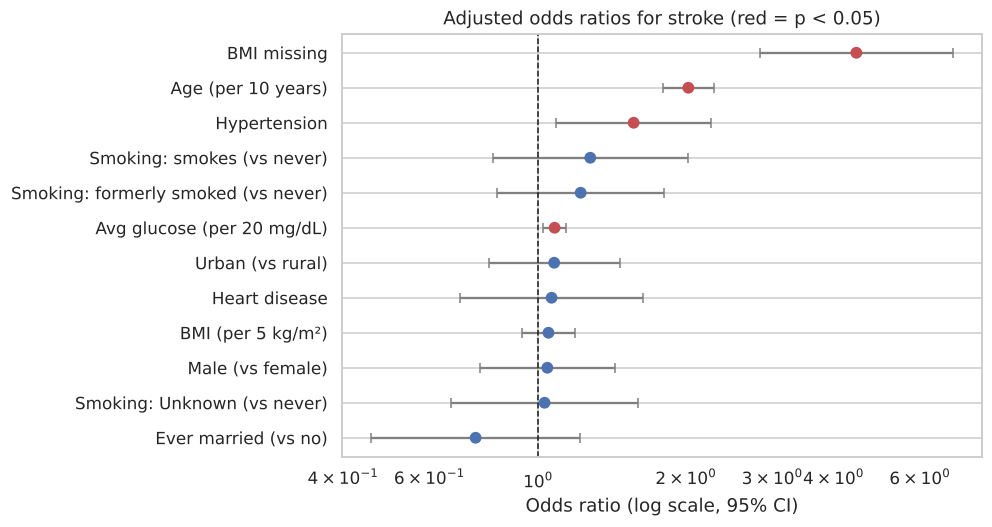

In [22]:
sm_df = X_train.copy()
sm_df['stroke'] = y_train.values
sm_df['bmi_missing'] = sm_df.bmi.isna().astype(int)
sm_df['bmi'] = sm_df.bmi.fillna(X_train.bmi.median())
sm_df['age_10y'] = sm_df.age / 10
sm_df['glucose_20'] = sm_df.avg_glucose_level / 20
sm_df['bmi_5'] = sm_df.bmi / 5

formula = ("stroke ~ age_10y + glucose_20 + bmi_5 + bmi_missing + hypertension + heart_disease"
           " + C(smoking_status, Treatment('never smoked')) + C(gender, Treatment('Female'))"
           " + C(ever_married, Treatment('No')) + C(Residence_type, Treatment('Rural'))")
logit = smf.logit(formula, data=sm_df).fit(disp=0)

nice = {'age_10y': 'Age (per 10 years)', 'glucose_20': 'Avg glucose (per 20 mg/dL)', 'bmi_5': 'BMI (per 5 kg/m²)',
        'bmi_missing': 'BMI missing', 'hypertension': 'Hypertension', 'heart_disease': 'Heart disease'}
def pretty(n):
    if n in nice: return nice[n]
    if 'smoking_status' in n: return 'Smoking: ' + n.split('T.')[1].rstrip(']') + ' (vs never)'
    if 'gender' in n: return 'Male (vs female)'
    if 'ever_married' in n: return 'Ever married (vs no)'
    if 'Residence' in n: return 'Urban (vs rural)'
    return n

ci = np.exp(logit.conf_int()); ci.columns = ['lo', 'hi']
orx = pd.DataFrame({'OR': np.exp(logit.params), 'lo': ci.lo, 'hi': ci.hi, 'p': logit.pvalues}).drop('Intercept')
orx.index = [pretty(i) for i in orx.index]
orx = orx.sort_values('OR')
display(orx.round(3))

fig, ax = plt.subplots(figsize=(7.5, 5))
sig = orx.p < 0.05
ax.errorbar(orx.OR, range(len(orx)), xerr=[orx.OR - orx.lo, orx.hi - orx.OR], fmt='none', ecolor='grey', capsize=3)
ax.scatter(orx.OR, range(len(orx)), c=np.where(sig, C_YES, C_NO), zorder=3, s=45)
ax.axvline(1, color='k', ls='--', lw=1); ax.set_xscale('log')
ax.set_yticks(range(len(orx))); ax.set_yticklabels(orx.index)
ax.set_xlabel('Odds ratio (log scale, 95% CI)'); ax.set_title('Adjusted odds ratios for stroke (red = p < 0.05)')
save_fig('10_odds_ratios')

- **Age** dominates: each additional decade roughly doubles the odds of stroke (OR ~2.0, 95% CI 1.8-2.3).
- **Hypertension** (OR ~1.6) and **average glucose** (OR ~1.08 per 20 mg/dL) carry modest independent risk.
- **Missing BMI** has the second-largest odds ratio (~4.5). This is not a biological effect: it flags how patients were assessed, which supports keeping the missing-indicator in the model. It also means a clinician-facing score built on this data would partly be learning a data-collection artefact.
- **Heart disease, smoking and marital status** looked strong in the raw EDA (e.g. 17% stroke rate with heart disease) but their adjusted confidence intervals include 1. Much of their crude association is explained by age. Heart disease is also rare here (n=276), so its CI is wide, and absence of significance is not evidence of no effect.

These are **associations in an observational dataset, not causal effects**.

### 8.2 Permutation importance (final model, test set)

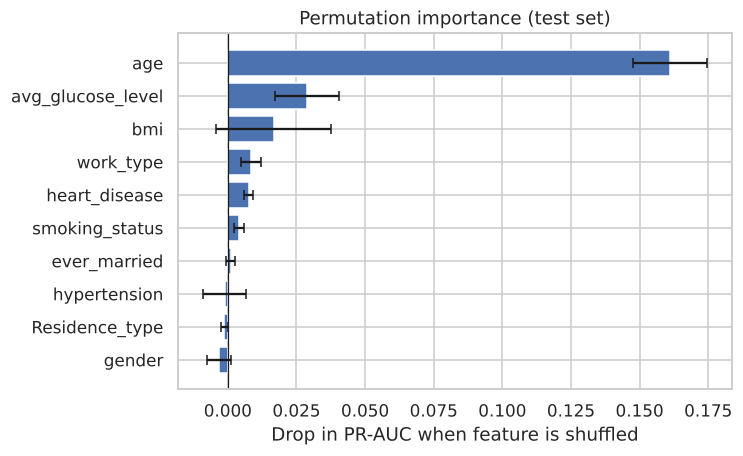

In [23]:
pi = permutation_importance(final_model, X_test, y_test, scoring='average_precision',
                            n_repeats=30, random_state=SEED, n_jobs=1)
imp = (pd.DataFrame({'feature': X_test.columns, 'mean': pi.importances_mean, 'sd': pi.importances_std})
         .sort_values('mean'))
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.barh(imp.feature, imp['mean'], xerr=imp['sd'], color=C_NO, capsize=3)
ax.axvline(0, color='k', lw=.8)
ax.set_xlabel('Drop in PR-AUC when feature is shuffled'); ax.set_title('Permutation importance (test set)')
save_fig('11_permutation_importance')

Permutation importance agrees with the odds-ratio analysis: **age** is by far the dominant driver (shuffling it removes most of the model's PR-AUC), followed by **average glucose**. BMI's bar is wide and partly reflects the missing-BMI signal (shuffling the column also shuffles which patients have missing values). Hypertension, residence, gender and marital status contribute nothing the model can reliably use once age is known; their bars straddle zero. This matches the finding that most factors are mediated by age.

## 9. Save model artefacts
The calibrated model, the chosen threshold and a small model card (metrics, versions, training details) are saved for the Streamlit demo (`app.py`).

In [24]:
joblib.dump(final_model, MODEL_DIR / 'stroke_model.joblib')
card = {
    'model_family': best_name,
    'best_params': {k.replace('model__', ''): (v if isinstance(v, (int, float, str, type(None))) else float(v))
                    for k, v in searches[best_name].best_params_.items()},
    'calibration': 'sigmoid, 5-fold CalibratedClassifierCV',
    'features': FEATURES,
    'threshold': threshold,
    'target_recall_on_training_oof': TARGET_RECALL,
    'training_prevalence': float(y_train.mean()),
    'n_train': int(len(y_train)), 'n_test': int(len(y_test)),
    'test_metrics': {k: {'estimate': float(report.loc[k, 'Estimate']),
                         'ci95': [float(report.loc[k, '95% CI low']), float(report.loc[k, '95% CI high'])]}
                     for k in report.index},
    'versions': {'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__, 'pandas': pd.__version__},
    'seed': SEED,
}
(MODEL_DIR / 'model_card.json').write_text(json.dumps(card, indent=2))
print(json.dumps({k: card[k] for k in ['model_family', 'threshold', 'test_metrics']}, indent=2))

{
  "model_family": "Random Forest",
  "threshold": 0.03685230953651799,
  "test_metrics": {
    "ROC-AUC": {
      "estimate": 0.837,
      "ci95": [
        0.782,
        0.89
      ]
    },
    "PR-AUC": {
      "estimate": 0.235,
      "ci95": [
        0.15,
        0.353
      ]
    },
    "Recall (sensitivity)": {
      "estimate": 0.8,
      "ci95": [
        0.686,
        0.911
      ]
    },
    "Specificity": {
      "estimate": 0.758,
      "ci95": [
        0.733,
        0.785
      ]
    },
    "Precision (PPV)": {
      "estimate": 0.145,
      "ci95": [
        0.104,
        0.189
      ]
    },
    "NPV": {
      "estimate": 0.987,
      "ci95": [
        0.978,
        0.995
      ]
    }
  }
}


## 10. Conclusions
### Held-out performance (1,022 patients, 50 strokes)

| Metric | Estimate | 95% bootstrap CI |
|---|---|---|
| ROC-AUC | 0.84 | 0.78 - 0.89 |
| PR-AUC (chance = 0.05) | 0.24 | 0.15 - 0.35 |
| Recall at chosen threshold | 0.80 | 0.69 - 0.91 |
| Specificity | 0.76 | 0.73 - 0.79 |
| Precision (PPV) | 0.145 | 0.10 - 0.19 |
| NPV | 0.987 | 0.98 - 0.995 |

At the threshold fixed beforehand to reach 80% recall, the model catches 40 of 50 strokes while flagging 27% of patients. A flagged patient has roughly a 1-in-7 chance of stroke (about 3x the 1-in-20 baseline); an unflagged patient has about a 1.3% chance. The low precision is not a bug: with 5% prevalence, even a decent classifier produces many false positives at high recall. The model is best viewed as a **risk-stratification** tool, not a diagnostic.

### What the analysis showed
1. **Accuracy hid the failure.** The original approach reported ~96% accuracy with zero strokes detected. Switching to PR-AUC / recall and an explicit threshold changed every conclusion.
2. **Age explains most of the signal.** An age-only model matches the full model's ROC-AUC; extra predictors give no statistically demonstrable gain on this test set.
3. **Missing BMI is informative.** Those patients have a ~4.6x higher stroke rate. Dropping them (as in the original notebook) would have discarded 16% of all positive cases.
4. **Model complexity does not help.** Logistic regression, random forest and XGBoost are within noise of each other after tuning; SMOTE adds nothing over class weights or threshold tuning.
5. **Leakage-free methodology matters.** Scaling and imputation are fitted inside CV folds, nominal variables are one-hot encoded, and the test set was used once.

### Limitations
- **Few positive cases** (249 overall, 50 in the test set): confidence intervals are wide, and a different split would shift the numbers noticeably.
- **Single public dataset** of unclear provenance, with no external or temporal validation. Performance in a real clinical population is unknown.
- **Informative missingness** in BMI and the large 'Unknown' smoking category suggest the data-collection process is entangled with outcome, so part of what the model learns may be an artefact.
- **Observational data:** odds ratios are associations, confounded mainly by age, not causal effects.
- The 80%-recall operating point is a stand-in for a real clinical cost trade-off, which would need domain input.

### Possible next steps
- Repeated stratified CV or nested CV for more stable estimates
- Decision-curve analysis to choose a threshold from an explicit cost / benefit ratio
- Validation on an independent cohort; subgroup performance checks (age bands, sex)
- Model-agnostic explanations (e.g. SHAP) and a fairness audit